# LAB 07 — Transformer Architecture


In [1]:
import sys, re, time, copy, random, platform
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from IPython.display import display

LAB_DIR = Path.cwd() / 'lab7' if (Path.cwd() / 'lab7' / 'transformer_block.py').is_file() else Path.cwd()
sys.path.insert(0, str(LAB_DIR.resolve()))
from transformer_block import positional_encoding, MultiHeadSelfAttention, TransformerBlock

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)
torch.use_deterministic_algorithms(True)
DEVICE = torch.device('cpu')
sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
print(f'Python {platform.python_version()} | PyTorch {torch.__version__} | {DEVICE} | 4 threads | seed={SEED}')

Python 3.12.7 | PyTorch 2.11.0+cpu | cpu | 4 threads | seed=42


#### 1. Bối cảnh

LAB 05: `Sequence → RNN/LSTM/GRU → Hidden state → Classification`.  
LAB 06: `Sequence → Q/K/V → Attention → Context representation → Classification`.  
LAB 07: `Embedding + Position → Multi-head attention → Add & Norm → FFN → Add & Norm → Pooling → Classification`.

**Làm thế nào ghép attention thành architecture hoàn chỉnh?** Bổ sung thông tin vị trí, nhiều phép chiếu attention, biến đổi phi tuyến theo token, đường residual và LayerNorm. Sau encoder, pooling chuyển biểu diễn từng token thành vector dùng cho classifier.

#### 6. Bài tập tính toán — Một attention head

Đề cho kích thước nhưng **không cho phần tử** của $X,W^Q,W^K,W^V$. Để tính cụ thể, chọn các ma trận minh họa sau, không coi đây là dữ kiện gốc:

$$X=\begin{bmatrix}1&0&1&0\\0&1&0&1\\1&1&0&0\end{bmatrix},\quad
W^Q=W^K=\begin{bmatrix}1&0\\0&1\\0&0\\0&0\end{bmatrix},\quad
W^V=\begin{bmatrix}0&0\\0&0\\1&0\\0&1\end{bmatrix}.$$

$$Q=K=\begin{bmatrix}1&0\\0&1\\1&1\end{bmatrix},\quad
V=\begin{bmatrix}1&0\\0&1\\0&0\end{bmatrix}.$$

$$S=\frac{1}{\sqrt2}\begin{bmatrix}1&0&1\\0&1&1\\1&1&2\end{bmatrix}
\approx\begin{bmatrix}.707107&0&.707107\\0&.707107&.707107\\.707107&.707107&1.414214\end{bmatrix}.$$

Softmax từng hàng: hàng đầu có mẫu số $2e^{1/\sqrt2}+1$, hàng cuối có mẫu số $2e^{1/\sqrt2}+e^{\sqrt2}$.

$$A\approx\begin{bmatrix}.401112&.197776&.401112\\.197776&.401112&.401112\\.248255&.248255&.503490\end{bmatrix},\quad
Z=AV\approx\begin{bmatrix}.401112&.197776\\.197776&.401112\\.248255&.248255\end{bmatrix}.$$

Shape: $Q,K,V:3\times2$; $S,A:3\times3$; $Z:3\times2$. Một head chính là attention ở LAB 06 sau các phép chiếu tuyến tính.

#### 7. Bài tập — Multi-head

Hai head đều có shape $T\times2$; ghép theo chiều feature được $T\times4$. Để đầu ra có chiều $d_{model}$, dùng $W^O\in\mathbb{R}^{4\times d_{model}}$.

**Vì sao cần concatenation trước khi áp dụng $W^O$?** Phép ghép giữ riêng đặc trưng của từng head; $W^O$ sau đó học cách trộn chúng và đưa về chiều cần cho residual. Cộng hai head ngay sẽ gộp các chiều tương ứng trước khi học cách phối hợp. Đây là cách viết chuẩn; về đại số có thể chia $W^O$ thành các khối rồi cộng các head đã chiếu mà không tạo tensor concat tường minh.

#### 8. Prediction trước experiment

Các dự đoán được ghi trước khi chạy thí nghiệm.

| # | Prediction | Reason | Confidence |
|---|---|---|---|
| 1 | Transformer xử lý các vị trí song song hơn RNN. | Q/K/V tính cùng lúc; RNN phụ thuộc state của timestep trước. Không đồng nghĩa luôn ít giây hơn. | Cao — 95% |
| 2 | Bỏ mọi thông tin vị trí, self-attention không biết thứ tự tuyệt đối. | Cùng trọng số áp dụng cho mọi vị trí; không có recurrence hay vị trí trong đầu vào. | Cao — 95% |
| 3 | Không PE, self-attention + mean pooling cho cùng vector với hai chuỗi là hoán vị của nhau. | Output token hoán vị tương ứng; lấy trung bình loại bỏ hoán vị. Giả sử eval, không causal mask, không yếu tố vị trí khác. | Cao — 95% |
| 4 | Hai head không nhất thiết học cùng pattern. | Các phép chiếu khác nhau; vẫn có thể trùng hoặc dư thừa. | Cao — 90% |
| 5 | Tăng số head không đảm bảo accuracy tăng. | Giữ d_model cố định làm d_k giảm; kết quả còn phụ thuộc dữ liệu và tối ưu. | Cao — 90% |
| 6 | Transformer không luôn nhanh hơn RNN ở mọi độ dài. | Attention có chi phí T², còn thời gian thực phụ thuộc phần cứng, batch và cách cài đặt. | Cao — 90% |

#### 9. Positional Encoding

$$PE(pos,2i)=\sin\left(\frac{pos}{10000^{2i/d}}\right),\qquad
PE(pos,2i+1)=\cos\left(\frac{pos}{10000^{2i/d}}\right).$$

Input encoder là $X'=X+PE$. Các chiều dùng tần số khác nhau để mã hóa vị trí. PE không tự đảm bảo mô hình hiểu quan hệ ngôn ngữ; nó cung cấp tín hiệu để mô hình có thể học sự khác nhau do thứ tự.

#### 10. Bài tập tính positional encoding

Với $d=4$, hai mẫu số là $10000^0=1$ và $10000^{1/2}=100$:

$$PE(pos)=[\sin(pos),\cos(pos),\sin(pos/100),\cos(pos/100)].$$

| pos | sin(pos) | cos(pos) | sin(pos/100) | cos(pos/100) |
|---:|---:|---:|---:|---:|
| 0 | 0.000000 | 1.000000 | 0.000000 | 1.000000 |
| 1 | 0.841471 | 0.540302 | 0.010000 | 0.999950 |
| 2 | 0.909297 | -0.416147 | 0.019999 | 0.999800 |

Mỗi vị trí có vector khác nhau; token giống nhau đặt ở vị trí khác nhau nhận đầu vào khác nhau.

#### 11. Experiment 1 — Positional encoding

Dùng embedding minh họa cố định 4 chiều cho `I`, `love`, `NLP`. So sánh `I love NLP` và `NLP love I`; các hàng của sequence thứ hai được đảo lại khi đối chiếu để so cùng token.

In [2]:
toy_embedding = torch.tensor([[1., 0., 0., 0.], [0., 1., 0., 0.], [0., 0., 1., 0.]])
permutation = torch.tensor([2, 1, 0])
pe3 = positional_encoding(3, 4)
input_original = toy_embedding + pe3
input_reversed = toy_embedding[permutation] + pe3
display(pd.DataFrame(pe3.numpy(), index=['pos 0', 'pos 1', 'pos 2']))
for name, matrix in [('Embedding: I love NLP', toy_embedding),
                     ('Embedding: NLP love I', toy_embedding[permutation]),
                     ('Embedding + PE: I love NLP', input_original),
                     ('Embedding + PE: NLP love I', input_reversed)]:
    print(name)
    display(pd.DataFrame(matrix.numpy()))
print('Max difference, aligned tokens, no PE:', (toy_embedding - toy_embedding[permutation][permutation]).abs().max().item())
print('Max difference, aligned tokens, with PE:', (input_original - input_reversed[permutation]).abs().max().item())

Embedding: I love NLP
Embedding: NLP love I
Embedding + PE: I love NLP
Embedding + PE: NLP love I
Max difference, aligned tokens, no PE: 0.0
Max difference, aligned tokens, with PE: 1.4161468744277954


,0,1,2,3
pos 0,0.000000,1.000000,0.000000,1.00000
pos 1,0.841471,0.540302,0.010000,0.99995
pos 2,0.909297,-0.416147,0.019999,0.99980


,0,1,2,3
0,1.0,0.0,0.0,0.0
1,0.0,1.0,0.0,0.0
2,0.0,0.0,1.0,0.0


,0,1,2,3
0,0.0,0.0,1.0,0.0
1,0.0,1.0,0.0,0.0
2,1.0,0.0,0.0,0.0


,0,1,2,3
0,1.000000,1.000000,0.000000,1.00000
1,0.841471,1.540302,0.010000,0.99995
2,0.909297,-0.416147,1.019999,0.99980


,0,1,2,3
0,0.000000,1.000000,1.000000,1.00000
1,0.841471,1.540302,0.010000,0.99995
2,1.909297,-0.416147,0.019999,0.99980


**Nếu chỉ dùng self-attention và không có positional information, tại sao thứ tự trở thành vấn đề?** 

Khi hoán vị token, embedding chỉ đổi thứ tự hàng. Self-attention không causal và không có tín hiệu vị trí cũng chỉ hoán vị output tương ứng: $F(PX)=PF(X)$. Mean pooling hai output đó giống nhau nên classifier không nhận biết khác biệt thứ tự. Khi thêm PE, cùng một từ ở vị trí khác được cộng vector khác; hai ma trận sau khi căn theo token không còn giống nhau. Mục 12 kiểm tra trực tiếp sau attention.

#### 12. Permutation experiment

S1 = **dog bites man**; 

S2 = **man bites dog**. 




In [3]:
torch.manual_seed(SEED)
permutation_attention = MultiHeadSelfAttention(d_model=4, n_heads=1).eval()
dog_bites_man = torch.tensor([[[1., 0., .5, 0.], [0., 1., 0., .5], [.2, 0., 1., 1.]]])
man_bites_dog = dog_bites_man[:, permutation]
permutation_rows = []
with torch.no_grad():
    for use_position in [False, True]:
        position = pe3[None] if use_position else torch.zeros_like(dog_bites_man)
        z1, _ = permutation_attention(dog_bites_man + position)
        z2, _ = permutation_attention(man_bites_dog + position)
        pooled1, pooled2 = z1.mean(1), z2.mean(1)
        permutation_rows.append({'Position': use_position,
                                 'Aligned token max difference': (z1-z2[:,permutation]).abs().max().item(),
                                 'Mean representation L2 difference': torch.linalg.vector_norm(pooled1-pooled2).item()})
        print('With PE' if use_position else 'Without PE')
        display(pd.DataFrame(torch.cat([pooled1, pooled2]).numpy(), index=['dog bites man', 'man bites dog']))
permutation_results = pd.DataFrame(permutation_rows)
display(permutation_results)

Without PE
With PE


,0,1,2,3
dog bites man,-0.358774,0.32161,-0.049071,0.620562
man bites dog,-0.358774,0.32161,-0.049071,0.620562


,0,1,2,3
dog bites man,-0.458073,0.288141,-0.320451,0.812724
man bites dog,-0.459582,0.251316,-0.300776,0.808720


,Position,Aligned token max difference,Mean representation L2 difference
0,False,5.960464e-08,3.725290e-09
1,True,8.758104e-02,4.196943e-02


**Kết quả thực nghiệm:** Không PE, sai khác L2 giữa hai vector mean là **3.725e-09**, ở mức sai số float32. Sau khi căn output theo token, sai khác lớn nhất là 5.960e-08. Có PE, khoảng cách giữa hai vector mean là **0.041969**, nên biểu diễn có thể phân biệt hai thứ tự trong ví dụ này.

Đây là tính **equivariance** ở mức token và **invariance** sau mean pooling khi không có vị trí; không phải output từng vị trí luôn giữ nguyên. Có PE phá vỡ tính bất biến đó trong thí nghiệm, nhưng không chứng minh model đã hiểu ai cắn ai. First-token pooling, causal mask hoặc tín hiệu vị trí khác sẽ thay đổi giả thiết của phép so sánh.

#### 13. Feed-Forward Network

$$FFN(x)=W_2\,\mathrm{ReLU}(W_1x+b_1)+b_2.$$

FFN dùng chung tham số tại mọi vị trí, biến đổi phi tuyến từng vector token theo chiều feature. Attention trộn thông tin giữa token; FFN không trực tiếp trộn vị trí, vì vậy không phải một attention mechanism khác.

#### 14. Bài tập tính FFN

$$x=\begin{bmatrix}1\\2\end{bmatrix},\quad W_1=I_2,\quad b_1=\begin{bmatrix}0\\-1\end{bmatrix}.$$
$$W_1x+b_1=\begin{bmatrix}1\\1\end{bmatrix},\qquad h=\mathrm{ReLU}([1,1]^T)=[1,1]^T.$$

Đề chưa cho $W_2,b_2$ nên không xác định được một giá trị số duy nhất cho $y$:

$$y=W_2\begin{bmatrix}1\\1\end{bmatrix}+b_2,\qquad y_j=(W_2)_{j1}+(W_2)_{j2}+(b_2)_j.$$

Nếu viết $W_2=\begin{bmatrix}a&b\\c&d\end{bmatrix},\ b_2=[e,f]^T$ thì $y=[a+b+e,c+d+f]^T$. Không tự gán giá trị thiếu để xem đó là đáp án của đề.

#### 15. Residual connection

**Nếu chỉ dùng $F(x)$, điều gì khác với $x+F(x)$?** Với $F(x)$, mọi thông tin phải đi qua phép biến đổi; với $x+F(x)$, nhánh identity truyền trực tiếp đầu vào và nhánh học chỉ cần tạo phần điều chỉnh. Hai nhánh phải cùng shape để cộng.

Gradient của residual có thêm thành phần identity: $\partial(x+F(x))/\partial x=I+\partial F/\partial x$. Điều này hỗ trợ truyền gradient và tối ưu mô hình sâu, nhưng không đảm bảo mọi thông tin được giữ nguyên sau các phép biến đổi tiếp theo.

**1. residual connection là gì?**
- Vấn đề: khi đi qua một lớp mạng, thông tin đầu vào có thể bị thay đổi sau mỗi lớp mạng.
- Residual connection là cơ chế cho phép thông tin đầu vào đi theo một đường truyền trực tiếp đến đầu ra, sau đó được cộng với kết quả của phép biến đổi
- y = x + F(x) :

trong đó:
- x là đầu vào của một khối biến đổi
- F(x) là kết quả sau khi đầu vào đi qua khối biến đổi
- y là đầu ra khi cộng hai thành phần 

Nhờ đó, đầu ra không chỉ chứa thông tin đã biến đổi mà cong giữa lại thành phần đầu vào 

**2. Tại sao cần residual connection?**
- giúp duy trì thông tin đầu vào: khi một vecto đi qua nhiều lớp biến đổi liên tiếp, mỗi lớp có thể làm thay đổi representation của vecto
- nếu chỉ truyền đầu ra của lớp trước sang lớp sai, thông tin ban đầu phải đi qua toàn bộ các phép biến đổi
- residual connection tạo thêm một đường truyền trực tiếp, giúpp thông tin đầu vào không phụ thuộc hoàn toàn vào phép biến đổi của lớp
- hỗ trợ quá trình tối ưu hóa: khi huấn luyện mạng neural netwodk, mo hình sử dụng thuật toán lan truyền ngược để tính gradient và cập nhật trọng số
- trong công thức đạo hàm của y = x + F(x), có xuất hiện thành phần 1 từ đường truyền trực tiếp x
=> điều này có nghĩa là gradient có thêm một đường truyền trực tiếp, không phụ thuộc vào đạo hàm của f

**3. residual connection được sử dụng như nào trong transformer**

- Residual connection được sử dụng hai lần trong một block
- lần 1: sau multi-head sefl attention
- lần 2: sau feed forward network

#### 16. Layer Normalization

Với input $B\times T\times d$, LayerNorm tính trung bình và phương sai trên $d$ feature **của từng token**, không trên batch hoặc toàn chuỗi:

$$LN(x)=\gamma\odot\frac{x-\mu}{\sqrt{\sigma^2+\epsilon}}+\beta.$$

Chuẩn hóa giúp kiểm soát thang giá trị bên trong block và hỗ trợ training ổn định. Bài dùng `nn.LayerNorm(d_model)` như đề cho phép.

#### 17. Core implementation — Transformer block

Cài đặt nằm trong `transformer_block.py`: `Linear` tạo Q/K/V → tách head → scaled dot-product → softmax → ghép head → output projection → Residual + LayerNorm → FFN → Residual + LayerNorm.

Không dùng `TransformerEncoderLayer`, `TransformerEncoder` hay `MultiheadAttention` dựng sẵn cho core. `valid` là mask token thật; PAD bị loại khỏi keys và khỏi pooling. Block encoder dùng attention hai chiều, không dùng causal mask.

In [4]:
import inspect
print(inspect.getsource(MultiHeadSelfAttention))
print(inspect.getsource(TransformerBlock))

class MultiHeadSelfAttention(nn.Module):
    def __init__(self, d_model, n_heads):
        super().__init__()
        if n_heads <= 0 or d_model % n_heads:
            raise ValueError('d_model phải chia hết cho n_heads > 0.')
        self.n_heads = n_heads
        self.d_k = d_model // n_heads
        self.wq = nn.Linear(d_model, d_model)
        self.wk = nn.Linear(d_model, d_model)
        self.wv = nn.Linear(d_model, d_model)
        self.wo = nn.Linear(d_model, d_model)

    def forward(self, x, valid=None):
        batch, length, dimension = x.shape
        if valid is None:
            valid = torch.ones(batch, length, dtype=torch.bool, device=x.device)
        if not valid.any(dim=1).all():
            raise ValueError('Mỗi sequence cần ít nhất một token thật.')

        def split_heads(projection):
            return projection(x).reshape(batch, length, self.n_heads, self.d_k).transpose(1, 2)

        q, k, v = [split_heads(layer) for layer in (self.wq, self.wk, self.wv)]
    

#### 18. Kiểm tra shape

Với $B=8,T=100,d_{model}=128,h=4$, có $d_k=32$. Chọn $d_{ff}=256$:

| Bước | Shape |
|---|---|
| X | 8 × 100 × 128 |
| Q/K/V trước tách head | 8 × 100 × 128 |
| Q/K/V sau tách head | 8 × 4 × 100 × 32 |
| Attention scores / weights | 8 × 4 × 100 × 100 |
| Context mỗi head | 8 × 4 × 100 × 32 |
| Concat / attention output | 8 × 100 × 128 |
| Residual + LayerNorm lần 1 | 8 × 100 × 128 |
| FFN hidden | 8 × 100 × 256 |
| FFN output | 8 × 100 × 128 |
| Block output | 8 × 100 × 128 |

In [5]:
torch.manual_seed(SEED)
shape_block = TransformerBlock(128, 4, 256).eval()
shape_x = torch.randn(8, 100, 128)
with torch.no_grad():
    q, k, v = [layer(shape_x).reshape(8, 100, 4, 32).transpose(1, 2)
               for layer in [shape_block.attention.wq, shape_block.attention.wk, shape_block.attention.wv]]
    scores = q @ k.transpose(-1, -2) / np.sqrt(32)
    context = scores.softmax(-1) @ v
    attended, _ = shape_block.attention(shape_x)
    residual = shape_block.norm1(shape_x + attended)
    ffn_hidden = shape_block.ffn[0](residual)
    ffn_output = shape_block.ffn(residual)
    shape_output = shape_block(shape_x)
display(pd.DataFrame([(name, tuple(tensor.shape)) for name, tensor in
    [('X', shape_x), ('Q', q), ('K', k), ('V', v), ('Scores', scores),
     ('Context per head', context), ('Attention output', attended),
     ('FFN hidden', ffn_hidden), ('FFN output', ffn_output), ('Output', shape_output)]], columns=['Tensor', 'Shape']))
assert shape_output.shape == shape_x.shape

,Tensor,Shape
0,X,"(8, 100, 128)"
1,Q,"(8, 4, 100, 32)"
2,K,"(8, 4, 100, 32)"
3,V,"(8, 4, 100, 32)"
4,Scores,"(8, 4, 100, 100)"
5,Context per head,"(8, 4, 100, 32)"
6,Attention output,"(8, 100, 128)"
7,FFN hidden,"(8, 100, 256)"
8,FFN output,"(8, 100, 128)"
9,Output,"(8, 100, 128)"


#### 19. Experiment 2 — Number of attention heads

Giữ `d_model=128`, thử `n_heads=1,2,4,8`; một encoder block, `d_ff=256`, mean pooling. Dùng IMDb của LAB 05, tiền xử lý và chỉ số chia tập như LAB 06: bỏ trùng sau clean, split 70/15/15 stratified seed 42; dùng 10.000 train, 2.000 validation, 2.000 test. Vocabulary chỉ fit train (`min_freq=2`).

Mọi run dùng embedding học từ đầu, batch 64, Adam lr=0.002, 5 epochs, gradient clipping 1.0; chọn checkpoint bằng **validation loss**. Độ dài cơ sở 64; riêng mục 22 thay đổi độ dài. Reset seed và thứ tự batch cho mỗi cấu hình. Dropout trong block 0.1, trước classifier 0.3. Thời gian đo trên CPU 4 threads, gồm train + validation + lưu checkpoint tốt nhất, không gồm preprocessing/test. Precision/Recall/F1 tính cho lớp positive. Đây là một lần chạy mỗi cấu hình, chưa đánh giá độ biến thiên qua nhiều seed.

In [6]:
def clean_text(text):
    return re.sub(r'\s+', ' ', str(text).replace('<br />', ' ')).strip()

def tokenize(text):
    return re.findall(r"[a-z0-9]+(?:'[a-z]+)?", clean_text(text).lower().replace('’', "'"))

raw = pd.read_csv(LAB_DIR.parent / 'dataset' / 'IMDB Dataset.csv')
df = pd.DataFrame({'text': raw.review.map(clean_text), 'label': (raw.sentiment == 'positive').astype(int), 'source_row': raw.index})
df = df.drop_duplicates('text').reset_index(drop=True)
idx_train_full, idx_rest = train_test_split(np.arange(len(df)), train_size=.70, random_state=SEED, stratify=df.label)
idx_valid_full, idx_test_full = train_test_split(idx_rest, train_size=.5, random_state=SEED, stratify=df.label.iloc[idx_rest])
subset = np.random.default_rng(SEED).choice(len(idx_train_full), size=10000, replace=False)
idx_train, idx_valid, idx_test = idx_train_full[subset], idx_valid_full[:2000], idx_test_full[:2000]
train_texts, valid_texts, test_texts = [df.text.iloc[idx].tolist() for idx in (idx_train, idx_valid, idx_test)]
y_train, y_valid, y_test = [df.label.iloc[idx].to_numpy() for idx in (idx_train, idx_valid, idx_test)]
train_tokens, valid_tokens, test_tokens = [[tokenize(t) for t in texts] for texts in (train_texts, valid_texts, test_texts)]
counter = Counter(word for tokens in train_tokens for word in tokens)
words = sorted((w for w, count in counter.items() if count >= 2), key=lambda w: (-counter[w], w))
vocab = {'<PAD>': 0, '<UNK>': 1, **{w: i+2 for i, w in enumerate(words)}}
DIM, D_FF, BASE_LENGTH, BATCH_SIZE, EPOCHS, LR = 128, 256, 64, 64, 5, .002
lengths = np.array([len(tokens) for tokens in train_tokens])

def encode_tokens(tokens, max_length):
    ids = [vocab.get(word, 1) for word in tokens[:max_length]] or [1]
    return ids + [0] * (max_length - len(ids))

dataset_cache = {}
def get_datasets(max_length):
    if max_length not in dataset_cache:
        dataset_cache[max_length] = [TensorDataset(torch.tensor([encode_tokens(t, max_length) for t in tokens], dtype=torch.long),
                                                  torch.tensor(labels, dtype=torch.long))
                                     for tokens, labels in [(train_tokens, y_train), (valid_tokens, y_valid), (test_tokens, y_test)]]
    return dataset_cache[max_length]

print(f'Raw={len(raw)}, clean={len(df)}, duplicates={len(raw)-len(df)}, vocabulary={len(vocab)}')
display(pd.DataFrame([{'Split': name, 'Samples': len(y), 'Negative': int((y==0).sum()), 'Positive': int((y==1).sum())}
                     for name, y in [('Train', y_train), ('Validation', y_valid), ('Test', y_test)]]))

Raw=50000, clean=49578, duplicates=422, vocabulary=33514


,Split,Samples,Negative,Positive
0,Train,10000,4981,5019
1,Validation,2000,992,1008
2,Test,2000,999,1001


In [7]:
class TransformerClassifier(nn.Module):
    def __init__(self, n_heads=4, max_length=BASE_LENGTH, pooling='mean'):
        super().__init__()
        if pooling not in ('mean', 'first'):
            raise ValueError('pooling phải là mean hoặc first')
        self.pooling = pooling
        self.max_length = max_length
        self.embedding = nn.Embedding(len(vocab), DIM, padding_idx=0)
        self.register_buffer('position', positional_encoding(max_length, DIM))
        self.block = TransformerBlock(DIM, n_heads, D_FF, dropout=.1)
        self.dropout = nn.Dropout(.3)
        self.classifier = nn.Linear(DIM, 2)

    def forward(self, ids, return_attention=False):
        valid = ids.ne(0)
        x = self.embedding(ids) + self.position[:ids.shape[1]]
        hidden, weights = self.block(x, valid, return_attention=True)
        if self.pooling == 'mean':
            pooled = (hidden * valid[:, :, None]).sum(1) / valid.sum(1, keepdim=True)
        else:
            pooled = hidden[:, 0]  # token thật đầu tiên; mô hình được train với cách lấy này
        logits = self.classifier(self.dropout(pooled))
        return (logits, weights) if return_attention else logits

In [8]:
@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    probabilities, labels, total_loss = [], [], 0.
    for ids, y in loader:
        logits = model(ids.to(DEVICE))
        total_loss += nn.functional.cross_entropy(logits, y.to(DEVICE), reduction='sum').item()
        probabilities.append(logits.softmax(-1)[:, 1].cpu().numpy())
        labels.append(y.numpy())
    y, probabilities = np.concatenate(labels), np.concatenate(probabilities)
    return total_loss / len(y), y, (probabilities >= .5).astype(int), probabilities

runs = {}
def train_run(name, factory, max_length=BASE_LENGTH, heads=None, pooling='last'):
    if name in runs:
        return runs[name]
    torch.manual_seed(SEED)
    model = factory().to(DEVICE)
    train_ds, valid_ds, test_ds = get_datasets(max_length)
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, generator=torch.Generator().manual_seed(SEED))
    valid_loader = DataLoader(valid_ds, batch_size=BATCH_SIZE)
    test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    best_loss, best_epoch, best_state = float('inf'), 0, None
    history = []
    started = time.perf_counter()
    for epoch in range(1, EPOCHS+1):
        model.train()
        loss_sum = 0.
        for ids, y in train_loader:
            ids, y = ids.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            loss = nn.functional.cross_entropy(model(ids), y)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.)
            optimizer.step()
            loss_sum += loss.item() * len(y)
        valid_loss, vy, vp, _ = evaluate(model, valid_loader)
        history.append({'epoch': epoch, 'train_loss': loss_sum / len(train_ds), 'valid_loss': valid_loss,
                        'valid_accuracy': accuracy_score(vy, vp)})
        if valid_loss < best_loss:
            best_loss, best_epoch, best_state = valid_loss, epoch, copy.deepcopy(model.state_dict())
        print(f'{name} | epoch {epoch}/{EPOCHS} | train={history[-1]["train_loss"]:.4f} | valid={valid_loss:.4f}', flush=True)
    elapsed = time.perf_counter() - started
    model.load_state_dict(best_state)
    test_loss, yt, yp, prob = evaluate(model, test_loader)
    row = {'Model': name, 'Heads': heads, 'd_k': DIM // heads if heads else None,
           'Length': max_length, 'Pooling': pooling, 'Parameters': sum(p.numel() for p in model.parameters()),
           'Training time (s)': elapsed, 'Accuracy': accuracy_score(yt, yp),
           'Precision': precision_score(yt, yp, zero_division=0), 'Recall': recall_score(yt, yp, zero_division=0),
           'F1': f1_score(yt, yp, zero_division=0), 'Best epoch': best_epoch}
    runs[name] = {'model': model, 'row': row, 'history': history, 'true': yt, 'pred': yp, 'prob': prob}
    return runs[name]

def transformer_run(heads=4, max_length=BASE_LENGTH, pooling='mean'):
    name = f'Transformer-h{heads}-T{max_length}-{pooling}'
    return train_run(name, lambda: TransformerClassifier(heads, max_length, pooling), max_length, heads, pooling)

In [9]:
head_runs = [transformer_run(heads=h) for h in [1, 2, 4, 8]]
heads_table = pd.DataFrame([run['row'] for run in head_runs])
display(heads_table[['Heads', 'd_k', 'Parameters', 'Training time (s)', 'Accuracy', 'F1']])
base_run = transformer_run(heads=4)
base_model = base_run['model'].eval()

Transformer-h1-T64-mean | epoch 1/5 | train=0.6544 | valid=0.6036
Transformer-h1-T64-mean | epoch 2/5 | train=0.5384 | valid=0.5985
Transformer-h1-T64-mean | epoch 3/5 | train=0.4062 | valid=0.5399
Transformer-h1-T64-mean | epoch 4/5 | train=0.2783 | valid=0.6038
Transformer-h1-T64-mean | epoch 5/5 | train=0.1725 | valid=0.7418
Transformer-h2-T64-mean | epoch 1/5 | train=0.6469 | valid=0.5934
Transformer-h2-T64-mean | epoch 2/5 | train=0.5361 | valid=0.5546
Transformer-h2-T64-mean | epoch 3/5 | train=0.4110 | valid=0.5427
Transformer-h2-T64-mean | epoch 4/5 | train=0.2778 | valid=0.6055
Transformer-h2-T64-mean | epoch 5/5 | train=0.1633 | valid=0.7598
Transformer-h4-T64-mean | epoch 1/5 | train=0.6382 | valid=0.6088
Transformer-h4-T64-mean | epoch 2/5 | train=0.5213 | valid=0.5598
Transformer-h4-T64-mean | epoch 3/5 | train=0.4047 | valid=0.5263
Transformer-h4-T64-mean | epoch 4/5 | train=0.2746 | valid=0.6072
Transformer-h4-T64-mean | epoch 5/5 | train=0.1576 | valid=0.7579
Transforme

,Heads,d_k,Parameters,Training time (s),Accuracy,F1
0,1,128,4422530,40.645846,0.7570,0.758209
1,2,64,4422530,42.045115,0.7475,0.751843
2,4,32,4422530,48.218693,0.7550,0.756703
3,8,16,4422530,52.719652,0.7505,0.747086


**Tăng số heads có đồng nghĩa với tăng representation dimension không?** Không. Tổng chiều output vẫn là **128**. Với h = 1, 2, 4, 8 thì d_k = 128, 64, 32, 16; tăng gấp đôi h làm d_k giảm một nửa.

| Heads | d_k | Parameters | Training time (s) | Accuracy | F1 |
| --- | --- | --- | --- | --- | --- |
| 1 | 128 | 4422530 | 40.6458 | 0.7570 | 0.7582 |
| 2 | 64 | 4422530 | 42.0451 | 0.7475 | 0.7518 |
| 4 | 32 | 4422530 | 48.2187 | 0.7550 | 0.7567 |
| 8 | 16 | 4422530 | 52.7197 | 0.7505 | 0.7471 |

Số tham số của bốn mô hình bằng nhau (**4,422,530**) vì các phép chiếu Q/K/V/O vẫn ánh xạ 128 → 128, chỉ thay cách chia các chiều thành head; embedding và FFN cũng giữ nguyên. Điều này không có nghĩa bộ nhớ attention bằng nhau: số ma trận T × T tăng theo h.

Accuracy không tăng đơn điệu theo số head trong lần chạy này. Không chọn số head dựa trên test để tiếp tục application; cấu hình 4 heads đã được cố định trước các thí nghiệm.

#### 20. Experiment 3 — Attention head diversity

Tiếp tục dùng Transformer 4 heads đã train ở mục 19. Trực quan hóa attention của câu **“The movie was surprisingly good despite a very slow beginning.”**. Hàng = query, cột = key; bỏ các vị trí PAD.

Độ tập trung được mô tả bằng entropy trung bình mỗi hàng chia cho log(số token): gần 0 là tập trung, gần 1 là phân tán. Sai khác tuyệt đối trung bình giữa hai ma trận giúp đối chiếu pattern trên chính câu này.

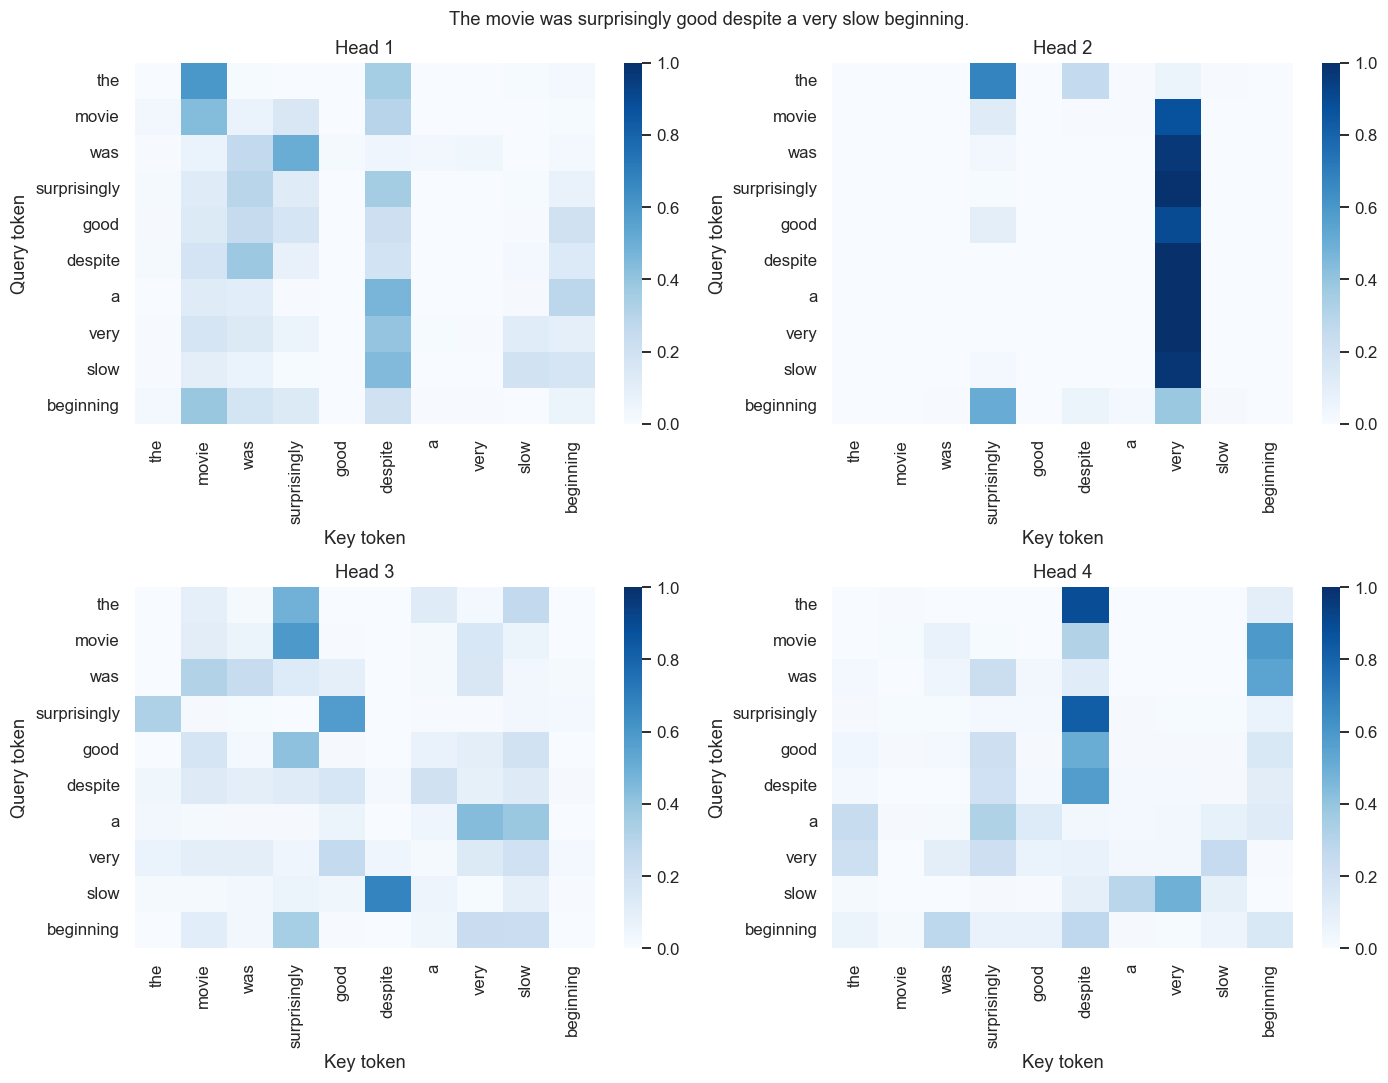

,Head,Normalized entropy,Mean row maximum,Top received token
0,1,0.636809,0.423077,despite
1,2,0.129825,0.888790,very
2,3,0.667114,0.430208,surprisingly
3,4,0.573771,0.527312,despite


,1,2,3,4
1,0.000000,0.183775,0.136007,0.119860
2,0.183775,0.000000,0.149433,0.175666
3,0.136007,0.149433,0.000000,0.152620
4,0.119860,0.175666,0.152620,0.000000


In [10]:
@torch.no_grad()
def inspect_text(text, model=base_model):
    model.eval()
    tokens = tokenize(text)[:model.max_length] or ['<UNK>']
    ids = torch.tensor([encode_tokens(tokens, model.max_length)], dtype=torch.long, device=DEVICE)
    logits, weights = model(ids, return_attention=True)
    return tokens, float(logits.softmax(-1)[0, 1]), weights[0, :, :len(tokens), :len(tokens)].cpu().numpy()

head_sentence = 'The movie was surprisingly good despite a very slow beginning.'
head_tokens, head_probability, head_weights = inspect_text(head_sentence)
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
head_statistics = []
for i, ax in enumerate(axes.flat):
    weights = head_weights[i]
    sns.heatmap(weights, ax=ax, xticklabels=head_tokens, yticklabels=head_tokens, cmap='Blues', vmin=0, vmax=1)
    ax.set(title=f'Head {i+1}', xlabel='Key token', ylabel='Query token')
    entropy = -(weights * np.log(np.maximum(weights, 1e-12))).sum(-1).mean() / np.log(len(head_tokens))
    head_statistics.append({'Head': i+1, 'Normalized entropy': float(entropy),
                            'Mean row maximum': float(weights.max(-1).mean()),
                            'Top received token': head_tokens[int(weights.mean(0).argmax())]})
fig.suptitle(head_sentence)
plt.tight_layout()
fig.savefig(LAB_DIR / 'attention_heads.png', dpi=160, bbox_inches='tight')
plt.show()
head_stats_table = pd.DataFrame(head_statistics)
head_distances = np.array([[np.abs(a-b).mean() for b in head_weights] for a in head_weights])
display(head_stats_table)
display(pd.DataFrame(head_distances, index=range(1, 5), columns=range(1, 5)))

**Multi-head có tạo pattern khác nhau trong experiment này không?** Có. Sai khác tuyệt đối trung bình giữa các cặp head nằm trong khoảng **0.1199–0.1838** trên câu đã chọn.

- **Head 2 tập trung nhất** theo entropy chuẩn hóa (0.1298); key nhận attention trung bình cao nhất là `very`.
- **Head 3 phân tán nhất** trong bốn head theo entropy (0.6671); key nhận attention trung bình cao nhất là `surprisingly`. “Phân tán nhất” ở đây chỉ là so sánh tương đối.
- Hai head gần nhau nhất là **1 và 4** (sai khác trung bình 0.1199); xa nhau nhất là **1 và 2** (0.1838).

Không có hai ma trận trùng hẳn trên câu này. Chưa đủ bằng chứng kết luận head nào dư thừa: pattern gần nhau trên một câu không chứng minh có thể bỏ head mà không đổi dự đoán. Không gán head là “syntax” hay “semantics”; attention heatmap chỉ thể hiện trọng số.

#### 21. Experiment 4 — Transformer vs RNN/LSTM

Train LSTM trên đúng các tập/vocabulary ở mục 19, embedding dimension 128, hidden size 128, cùng max_length=64, batch size, optimizer, learning rate và epochs. LSTM lấy hidden state ở token thật cuối cùng. Transformer dùng mean pooling sau encoder.

Transformer 4 heads được **dùng lại** từ mục 19; không train lại để điền bảng. Số tham số khác nhau do kiến trúc; không khẳng định đây là thí nghiệm chỉ thay một thành phần.

In [11]:
class LSTMClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.embedding = nn.Embedding(len(vocab), DIM, padding_idx=0)
        self.lstm = nn.LSTM(DIM, DIM, batch_first=True)
        self.dropout = nn.Dropout(.3)
        self.classifier = nn.Linear(DIM, 2)

    def forward(self, ids):
        lengths = ids.ne(0).sum(1)
        hidden, _ = self.lstm(self.embedding(ids))
        last = hidden[torch.arange(len(ids), device=ids.device), lengths-1]
        return self.classifier(self.dropout(last))

lstm_run = train_run('LSTM', LSTMClassifier)
comparison_table = pd.DataFrame([lstm_run['row'], base_run['row']])
display(comparison_table[['Model', 'Parameters', 'Training time (s)', 'Accuracy', 'Precision', 'Recall', 'F1']])

LSTM | epoch 1/5 | train=0.6900 | valid=0.6790
LSTM | epoch 2/5 | train=0.6115 | valid=0.6568
LSTM | epoch 3/5 | train=0.5000 | valid=0.6081
LSTM | epoch 4/5 | train=0.3407 | valid=0.6458
LSTM | epoch 5/5 | train=0.2058 | valid=0.7364


,Model,Parameters,Training time (s),Accuracy,Precision,Recall,F1
0,LSTM,4422146,27.886580,0.7145,0.699443,0.753247,0.725349
1,Transformer-h4-T64-mean,4422530,48.218693,0.7550,0.752221,0.761239,0.756703


| Model | Parameters | Training time (s) | Accuracy | Precision | Recall | F1 |
| --- | --- | --- | --- | --- | --- | --- |
| LSTM | 4422146 | 27.8866 | 0.7145 | 0.6994 | 0.7532 | 0.7253 |
| Transformer (4 heads, mean) | 4422530 | 48.2187 | 0.7550 | 0.7522 | 0.7612 | 0.7567 |

**Sự khác biệt performance có thể xuất phát từ những thành phần architecture nào?** LSTM nén chuỗi vào state ở token cuối, trong khi Transformer cho mỗi token tương tác trực tiếp với các token khác rồi lấy mean toàn chuỗi. Multi-head, PE, FFN phi tuyến, residual và LayerNorm cũng thay đổi cách tạo và tối ưu representation. Những thành phần này thay đổi đồng thời, nên không thể quy toàn bộ chênh lệch cho riêng attention hay riêng PE.

Transformer có F1 **0.7567**, LSTM **0.7253**; thời gian tương ứng **48.22s** và **27.89s**. Kết quả chỉ áp dụng cho cấu hình, CPU và seed đã nêu. Cùng giới hạn 64 token làm cả hai mất phần đuôi review dài; Transformer không mặc nhiên thắng hoặc nhanh hơn trong mọi điều kiện.

#### 22. Experiment 5 — Sequence length

Giữ Transformer 4 heads + mean pooling, thay `max_length=32,64,128,256`. Run T=64 dùng lại; các độ dài khác train riêng từ đầu với cùng seed, dữ liệu và cấu hình tối ưu.

**Tokens retained** = tổng $\min(\text{độ dài review},T)$ / tổng token gốc trên train. **Attention memory** = dung lượng lý thuyết của **một tensor** attention float32 có shape $B\times h\times T\times T$: $4BhT^2$ bytes, với batch đầy đủ $B=64,h=4$. Đây không phải peak RAM hoặc toàn bộ bộ nhớ training; chưa cộng Q/K/V, scores khác, gradient và optimizer.

In [12]:
length_rows = []
for max_length in [32, 64, 128, 256]:
    run = transformer_run(max_length=max_length)
    length_rows.append({'Length': max_length,
                        'Tokens retained': np.minimum(lengths, max_length).sum() / lengths.sum(),
                        'Attention elements/head': max_length**2,
                        'Attention memory (MiB)': 4 * BATCH_SIZE * 4 * max_length**2 / 2**20,
                        'Training time (s)': run['row']['Training time (s)'], 'F1': run['row']['F1']})
length_table = pd.DataFrame(length_rows)
display(length_table)

Transformer-h4-T32-mean | epoch 1/5 | train=0.6557 | valid=0.6065
Transformer-h4-T32-mean | epoch 2/5 | train=0.5645 | valid=0.5985
Transformer-h4-T32-mean | epoch 3/5 | train=0.4670 | valid=0.5900
Transformer-h4-T32-mean | epoch 4/5 | train=0.3513 | valid=0.6876
Transformer-h4-T32-mean | epoch 5/5 | train=0.2347 | valid=0.8985
Transformer-h4-T128-mean | epoch 1/5 | train=0.6039 | valid=0.5100
Transformer-h4-T128-mean | epoch 2/5 | train=0.4500 | valid=0.4437
Transformer-h4-T128-mean | epoch 3/5 | train=0.3176 | valid=0.4220
Transformer-h4-T128-mean | epoch 4/5 | train=0.1949 | valid=0.5019
Transformer-h4-T128-mean | epoch 5/5 | train=0.0878 | valid=0.7673
Transformer-h4-T256-mean | epoch 1/5 | train=0.5764 | valid=0.4906
Transformer-h4-T256-mean | epoch 2/5 | train=0.3930 | valid=0.3668
Transformer-h4-T256-mean | epoch 3/5 | train=0.2532 | valid=0.3608
Transformer-h4-T256-mean | epoch 4/5 | train=0.1324 | valid=0.5045
Transformer-h4-T256-mean | epoch 5/5 | train=0.0605 | valid=0.6389


,Length,Tokens retained,Attention elements/head,Attention memory (MiB),Training time (s),F1
0,32,0.139380,1024,1.0,29.660765,0.716628
1,64,0.275618,4096,4.0,48.218693,0.756703
2,128,0.518261,16384,16.0,103.243524,0.812314
3,256,0.771938,65536,64.0,226.771664,0.819466


| Length | Tokens retained | Attention memory (MiB) | Training time (s) | F1 |
| --- | --- | --- | --- | --- |
| 32 | 0.1394 | 1.0000 | 29.6608 | 0.7166 |
| 64 | 0.2756 | 4.0000 | 48.2187 | 0.7567 |
| 128 | 0.5183 | 16.0000 | 103.2435 | 0.8123 |
| 256 | 0.7719 | 64.0000 | 226.7717 | 0.8195 |

**Tại sao không đơn giản tăng sequence length để giải quyết mọi vấn đề?** Tăng từ 128 lên 256 làm số phần tử attention mỗi head tăng từ **16.384 lên 65.536 (4 lần)**. Với batch 64, 4 heads, một tensor float32 tăng từ **16 MiB lên 64 MiB**; training còn cần nhiều tensor khác. Thời gian thực không nhất thiết tăng đúng 4 lần vì còn embedding, projections, FFN và optimizer.

Tỷ lệ giữ token tăng từ **13.94%** ở T=32 lên **77.19%** ở T=256. F1 lần lượt là **0.7166, 0.7567, 0.8123, 0.8195**. Thêm context có thể giúp, nhưng cũng tăng chi phí và đưa thêm thông tin không liên quan. T=256 vẫn cắt các review dài hơn 256 token; chỉ tăng T không tự giải quyết phủ định, nhập nhằng hoặc thiếu dữ liệu học.

#### 23. Application — Transformer text classification

`Raw text → Tokenizer → IDs → Embedding + PE → Transformer block → Masked mean pooling → Linear → Softmax → Prediction`.

Dùng tiếp Transformer 4 heads, T=64 ở mục 19; không chọn model theo test. Thử năm loại câu theo đề. Nhãn kỳ vọng do người viết đặt để diễn giải các ví dụ, không phải gold label của IMDb; câu ambiguous không gán một nhãn đúng duy nhất. P(predicted) là xác suất softmax của nhãn dự đoán, chưa được hiệu chỉnh độ tin cậy.

In [13]:
application_cases = [
    ('Short', 'I really enjoyed this movie.', 'positive'),
    ('Long', 'I watched this movie with my family on a quiet evening, expecting a familiar story and little more. '
     'The opening takes its time to introduce the town, the neighbors, and the problems that bring everyone together. '
     'Several scenes follow ordinary conversations at home, at work, and during a long journey. '
     'Although the pace is slow and some scenes repeat information, the performances feel sincere, '
     'the characters become more interesting, and the ending rewards the time spent with them. '
     'I left feeling moved and would gladly recommend it.', 'positive'),
    ('Negation', 'I did not enjoy this movie at all.', 'negative'),
    ('Contrast', 'The beginning was boring, but the ending was excellent and I loved the movie overall.', 'positive'),
    ('Ambiguous', 'The movie was neither particularly good nor particularly bad; some moments worked and others did not.', 'ambiguous'),
]
application_rows = []
for category, text, expected in application_cases:
    tokens, probability, weights = inspect_text(text)
    predicted = 'positive' if probability >= .5 else 'negative'
    application_rows.append({'Type': category, 'Text': text, 'Expected': expected, 'Predicted': predicted,
                             'P(positive)': probability, 'P(predicted)': max(probability, 1-probability),
                             'Original tokens': len(tokenize(text)), 'Seen tokens': len(tokens)})
application_table = pd.DataFrame(application_rows)
display(application_table.drop(columns='Text'))
for row in application_rows:
    print(f"{row['Type']}: {row['Text']}\n  {row['Predicted']} | P(predicted)={row['P(predicted)']:.4f}")

Short: I really enjoyed this movie.
  positive | P(predicted)=0.6806
Long: I watched this movie with my family on a quiet evening, expecting a familiar story and little more. The opening takes its time to introduce the town, the neighbors, and the problems that bring everyone together. Several scenes follow ordinary conversations at home, at work, and during a long journey. Although the pace is slow and some scenes repeat information, the performances feel sincere, the characters become more interesting, and the ending rewards the time spent with them. I left feeling moved and would gladly recommend it.
  positive | P(predicted)=0.9858
Negation: I did not enjoy this movie at all.
  negative | P(predicted)=0.8420
Contrast: The beginning was boring, but the ending was excellent and I loved the movie overall.
  negative | P(predicted)=0.8892
Ambiguous: The movie was neither particularly good nor particularly bad; some moments worked and others did not.
  negative | P(predicted)=0.9898


,Type,Expected,Predicted,P(positive),P(predicted),Original tokens,Seen tokens
0,Short,positive,positive,0.680623,0.680623,5,5
1,Long,positive,positive,0.985841,0.985841,87,64
2,Negation,negative,negative,0.157959,0.842041,8,8
3,Contrast,positive,negative,0.110832,0.889168,15,15
4,Ambiguous,ambiguous,negative,0.010240,0.989760,16,16


| Loại | Kỳ vọng | Dự đoán | P(positive) | Token gốc → thấy |
| --- | --- | --- | --- | --- |
| Short | positive | positive | 0.6806 | 5 → 5 |
| Long | positive | positive | 0.9858 | 87 → 64 |
| Negation | negative | negative | 0.1580 | 8 → 8 |
| Contrast | positive | negative | 0.1108 | 15 → 15 |
| Ambiguous | ambiguous | negative | 0.0102 | 16 → 16 |

Model khớp nhãn kỳ vọng ở **3/4** ví dụ có sentiment định hướng rõ; đây chỉ là nhóm câu minh họa, không phải accuracy trên test. Với negation cần xét phạm vi của “not”; với contrast cần phân biệt đánh giá phần đầu và đánh giá tổng thể, không chỉ tìm từ tích cực/tiêu cực.

Câu dài có **87** token nhưng model chỉ thấy **64**; phần kết luận cuối bị cắt có thể làm mất bằng chứng sentiment. Câu ambiguous chứa đánh giá lẫn lộn, trong khi classifier bắt buộc chọn một trong hai lớp; không coi lựa chọn đó là chắc chắn đúng/sai. Xác suất softmax cao cũng không tự chứng minh dự đoán đáng tin cậy.

#### 24. Pooling

Encoder trả về $H\in\mathbb{R}^{T\times d}$. Với mask $m_t=1$ ở token thật, mean pooling dùng:

$$h_{mean}=\frac{\sum_t m_tH_t}{\sum_t m_t}.$$

Không chia cho độ dài đã pad và không cộng vector PAD. Cách này gom thông tin từ mọi token thật thành một vector $d$ chiều. First-token pooling lấy $H_0$, đã được contextualize qua self-attention. Nó có thể đóng vai trò đọc toàn chuỗi nếu được huấn luyện với classifier đó; **không mặc định tương đương token [CLS] của BERT**. Bài không thêm [CLS] để giữ tokenizer và số token giống nhau.

#### 25. Experiment 6 — Pooling strategy

So sánh mean với **first-token (CLS-style, không thêm token [CLS])**, đúng lựa chọn first-token mà đề cho phép. Cả hai model có cùng kiến trúc, tham số khởi tạo, seed, dữ liệu, max_length=64 và lịch training; chỉ thay phép lấy sequence representation. Mean dùng lại run 4 heads, first-token được train riêng, không đổi pooling đột ngột ở inference.

In [14]:
first_run = transformer_run(pooling='first')
pooling_table = pd.DataFrame([base_run['row'], first_run['row']])
display(pooling_table[['Pooling', 'Accuracy', 'F1', 'Training time (s)']])

Transformer-h4-T64-first | epoch 1/5 | train=0.6727 | valid=0.6267
Transformer-h4-T64-first | epoch 2/5 | train=0.5993 | valid=0.6114
Transformer-h4-T64-first | epoch 3/5 | train=0.5411 | valid=0.6404
Transformer-h4-T64-first | epoch 4/5 | train=0.4630 | valid=0.6534
Transformer-h4-T64-first | epoch 5/5 | train=0.3717 | valid=0.8393


,Pooling,Accuracy,F1,Training time (s)
0,mean,0.755,0.756703,48.218693
1,first,0.646,0.599548,43.146701


| Pooling | Accuracy | F1 | Training time (s) |
| --- | --- | --- | --- |
| Mean | 0.7550 | 0.7567 | 48.2187 |
| First-token / CLS-style | 0.6460 | 0.5995 | 43.1467 |

**Cách lấy sequence representation có ảnh hưởng classification không?** Có trong lần chạy này: accuracy chênh **0.1090**, F1 chênh **0.1572**. Mean lấy thông tin từ tất cả vị trí thật; first-token buộc representation ở vị trí đầu mang thông tin cho classifier. Cả hai nhận gradient khác nhau qua pooling, nên quá trình học cũng khác.

Không suy rộng rằng một cách luôn tốt hơn. First-token ở đây là token thật đầu câu được contextualize, không phải [CLS] đã pretrained; không dùng kết quả này để đánh giá pooling của BERT.

#### 26. Error analysis

Chọn ngẫu nhiên, seed 42, đúng 3 mẫu dự đoán đúng và 3 mẫu sai của Transformer 4 heads + mean, T=64 trên test. Giữ `test_index` và `source_row` để truy lại dữ liệu. Đối chiếu nhãn review đầy đủ với phần tối đa 64 token model nhìn thấy.

Attention nhận bởi key được tính bằng trung bình trên query thật và các head, dùng để mô tả pattern; không phải điểm đóng góp nhân quả. Phần nhận xét phân biệt quan sát đầu ra với giả thuyết về negation, contrast, truncation, từ hiếm, sentiment mơ hồ, thuật ngữ điện ảnh và noise.

In [15]:
rng_errors = np.random.default_rng(SEED)
correct_indices = rng_errors.choice(np.flatnonzero(base_run['pred'] == y_test), 3, replace=False)
incorrect_indices = rng_errors.choice(np.flatnonzero(base_run['pred'] != y_test), 3, replace=False)
error_examples = []
for group, indices in [('C', correct_indices), ('E', incorrect_indices)]:
    for number, index in enumerate(indices, 1):
        index = int(index)
        tokens, probability, weights = inspect_text(test_texts[index])
        received = weights.mean(axis=(0, 1))
        top = np.argsort(-received, kind='stable')[:5]
        example = {'ID': f'{group}{number}', 'test_index': index, 'source_row': int(df.iloc[idx_test[index]].source_row),
                   'True': int(y_test[index]), 'Predicted': int(base_run['pred'][index]), 'P(positive)': probability,
                   'Original tokens': len(test_tokens[index]), 'Seen tokens': len(tokens),
                   'UNK': sum(word not in vocab for word in tokens),
                   'Top attention': [(tokens[j], int(j), float(received[j])) for j in top],
                   'Top per head': [[(tokens[j], int(j), float(head.mean(0)[j]))
                                     for j in np.argsort(-head.mean(0), kind='stable')[:3]] for head in weights],
                   'Seen text': ' '.join(tokens), 'Full text': test_texts[index]}
        error_examples.append(example)
display(pd.DataFrame(error_examples)[['ID', 'test_index', 'source_row', 'True', 'Predicted', 'P(positive)', 'Original tokens', 'Seen tokens', 'UNK', 'Top attention']])
for example in error_examples:
    print(example['ID'], '| model sees:', example['Seen text'])
    print('Top keys per head:', example['Top per head'])

C1 | model sees: wracked with guilt after a lot of things felt apart on that ledge an ace mountain rescue climber gabriel walker stallone comes back for his girlfriend jessie janine turner while over the cloudy skies where the weather looks a bit threatening a spectacularly precarious mid air hijacking goes wrong and 100 million taken from a treasury department plane get lost in the middle of
Top keys per head: [[('100', 50, 0.5623048543930054), ('looks', 37, 0.09200017154216766), ('over', 30, 0.07313401997089386)], [('100', 50, 0.8650153279304504), ('precarious', 43, 0.029918164014816284), ('things', 7, 0.024397777393460274)], [('things', 7, 0.5737679600715637), ('hijacking', 46, 0.11987411975860596), ('walker', 19, 0.034739311784505844)], [('guilt', 2, 0.14403682947158813), ('and', 49, 0.10057833045721054), ('wrong', 48, 0.10055220872163773)]]
C2 | model sees: i found the movie at my local video store and i was surprised to see it on dvd i had heard about the explicit sex scenes grue

,ID,test_index,source_row,True,Predicted,P(positive),Original tokens,Seen tokens,UNK,Top attention
0,C1,1317,28627,1,1,0.823228,177,64,2,"[(100, 50, 0.3618239164352417), (things, 7, 0...."
1,C2,171,3174,0,0,0.207422,211,64,0,"[(cheap, 47, 0.2142452597618103), (poorly, 60,..."
2,C3,1544,44526,0,0,0.011628,639,64,1,"[(worst, 5, 0.2741403877735138), (disappointin..."
3,E1,193,15212,1,0,0.179555,447,64,0,"[(shallow, 1, 0.21739564836025238), (looks, 32..."
4,E2,1400,48743,1,0,0.384004,202,64,0,"[(zero, 2, 0.19557881355285645), (stop, 19, 0...."
5,E3,1712,17315,1,0,0.146738,138,64,0,"[(bad, 56, 0.2194392830133438), (obviously, 15..."


### Bảng 3 correct + 3 incorrect

Nhãn `0 = negative`, `1 = positive`; vị trí token tính từ 0. Trọng số trong phần nhận xét là attention nhận bởi key, trung bình trên các query thật và 4 heads.

| Mẫu | test_index / source_row | True → Pred | P(positive) | Token gốc → thấy | UNK | Top-3 attention nhận |
|---|---|---|---:|---|---:|---|
| C1 | 1317 / 28627 | 1 → 1 | 0.8232 | 177 → 64 | 2 | 100 (0.3618), things (0.1584), hijacking (0.0448) |
| C2 | 171 / 3174 | 0 → 0 | 0.2074 | 211 → 64 | 0 | cheap (0.2142), poorly (0.2005), notorious (0.1201) |
| C3 | 1544 / 44526 | 0 → 0 | 0.0116 | 639 → 64 | 1 | worst (0.2741), disappointing (0.2588), whatsoever (0.0518) |
| E1 | 193 / 15212 | 1 → 0 | 0.1796 | 447 → 64 | 0 | shallow (0.2174), looks (0.1560), because (0.1140) |
| E2 | 1400 / 48743 | 1 → 0 | 0.3840 | 202 → 64 | 0 | zero (0.1956), stop (0.1380), sequel (0.1310) |
| E3 | 1712 / 17315 | 1 → 0 | 0.1467 | 138 → 64 | 0 | bad (0.2194), obviously (0.1312), love (0.1147) |

### C1 — Dự đoán đúng, nhưng attention chủ yếu ở phần kể cốt truyện

- **Quan sát:** Model dự đoán positive, P(positive)=0.8232. Trong 64 token đầu, review đang kể về người leo núi cứu hộ và vụ cướp tiền; từ `100` ở vị trí 50 nhận attention cao nhất. Head 1 và 2 đều đặt nhiều trọng số vào token này. Từ `best` trong lời khen ở cuối review nằm tại vị trí 173, ngoài phần model nhìn thấy.
- **Diễn giải:** Nhãn đúng không chứng minh model đã đọc được lời khen kết luận. `100`, `things`, `hijacking` không phải những bằng chứng sentiment rõ ràng mà người đọc ưu tiên. Không thể dùng heatmap này để kết luận model hiểu toàn bộ đánh giá.
- **Từ hiếm/noise:** `wracked` xuất hiện một lần trong train nên bị loại bởi min_freq=2; `cloudy` không có trong train. Cả hai thành UNK. Review có câu rất dài và ít dấu câu, nhưng chưa có thí nghiệm tách riêng tác động của những yếu tố này.

### C2 — Các từ phê bình xuất hiện trong attention

- **Quan sát:** True negative, dự đoán negative; P(positive)=0.2074. Đoạn model thấy có “cheap and fake” và “poorly written”. `cheap` (vị trí 47, 0.2142) và `poorly` (60, 0.2005) là hai key nhận trọng số trung bình lớn nhất. Head 2 tập trung vào `cheap`, head 3 tập trung vào `poorly`.
- **Diễn giải:** Attention ở đây trùng với các từ phê bình mà người đọc xem là quan trọng. `laughing` cũng nằm trong top-5 nhưng trong ngữ cảnh này là phản ứng chê tác phẩm, không đơn giản là lời khen phim hài.
- **Thuật ngữ lĩnh vực:** “set decorations” và “art direction” cho biết đối tượng bị chê. Review bị cắt từ 211 còn 64 token, nhưng phần đầu đã có bằng chứng negative rõ. Không suy ra truncation luôn vô hại từ một mẫu dự đoán đúng.

### C3 — Sentiment negative rõ từ đầu, dù review rất dài

- **Quan sát:** True negative, dự đoán negative với P(positive)=0.0116. Các key `worst` (5, 0.2741), `disappointing` (50, 0.2588) và `weak` (14, 0.0468) xuất hiện trong nhóm attention cao. Head 1 nhấn `worst`; head 2 và 3 nhấn `disappointing`.
- **Diễn giải:** Những từ này phù hợp với nhận định negative của người đọc. Đoạn đầu cũng có “not only ... but ...” và “does not fight”; dự đoán đúng chưa chứng minh model xử lý đúng phạm vi phủ định, vì các từ đánh giá trực tiếp đã rất mạnh.
- **Độ dài/từ riêng:** 639 token bị cắt còn 64. `kazaf` là tên nhân vật không xuất hiện trong vocabulary train. Model vẫn đoán đúng mẫu này; không thể coi mọi UNK hoặc mọi review dài đều gây lỗi.

### E1 — Lời khen kiểu phim cult và sự chuyển ý

- **Quan sát:** Review positive nhưng dự đoán negative, P(positive)=0.1796. Đầu review nói về ấn tượng trước khi xem rồi chuyển sang “trashy, cheesy, campy and enormously fun”. `shallow` (1, 0.2174) nhận attention trung bình cao nhất; `fun` (58, 0.0391) vẫn nằm trong top-5, nhưng thấp hơn. Head 2 tập trung mạnh vào `shallow`.
- **Diễn giải:** `shallow` mô tả nhận xét ban đầu của người viết, không phải kết luận về chất lượng phim. Các từ `cheesy`, `campy` có thể đi cùng thái độ yêu thích phim cult, nên sentiment phụ thuộc ngữ cảnh và đối tượng đánh giá. Đây là giả thuyết về lỗi chuyển ý/thuật ngữ lĩnh vực, không phải bằng chứng attention ở `shallow` gây ra dự đoán.
- **Truncation:** Model thấy lời khen `fun` nhưng không thấy nhiều lời khen tiếp theo và kết luận “must-see” ở cuối review 447 token. Do vậy không nên giải thích lỗi chỉ bằng việc mọi bằng chứng positive đều bị cắt. Mẫu này không có UNK trong đoạn được đọc.

### E2 — Phủ định làm đảo nghĩa của cụm “did not stop”

- **Quan sát:** True positive, dự đoán negative, P(positive)=0.3840. Người viết bắt đầu bằng “zero interest” về thể loại âm nhạc, rồi nói “however, that did not stop me from appreciating this fantastic comedy”. `zero` (2, 0.1956), `stop` (19, 0.1380) và `sequel` (30, 0.1310) nằm trong top attention. `fantastic` ở vị trí 24 và `hilarious` ở 53 đều nằm trong input, nhưng không thuộc top-5 attention trung bình.
- **Diễn giải:** Phải phân biệt sở thích âm nhạc với đánh giá phim, đồng thời hiểu “did not stop” là phủ định việc cản trở sự yêu thích. Model có thể chưa tổng hợp tốt phạm vi phủ định và chuyển ý; heatmap chỉ cho thấy phân phối trọng số, chưa xác định nguyên nhân lỗi.
- **Domain/noise:** “This Is Spinal Tap” là tên phim dùng để so sánh; `spinal` có attention cao nhưng không nên đọc như một từ sentiment độc lập. Review có vài cấu trúc thiếu từ/sai ngữ pháp. Cả 64 token đầu không có UNK; không có căn cứ quy lỗi này cho từ ngoài vocabulary.

### E3 — Phần chê được giữ lại, phần kết luận tích cực bị cắt

- **Quan sát:** True positive, dự đoán negative, P(positive)=0.1467. Input chứa “continuity errors” và “supporting cast was really bad”; `bad` (56, 0.2194) có attention trung bình cao nhất, head 2 dành khoảng 0.8217 attention nhận trung bình cho token này. `love` (32, 0.1147) cũng xuất hiện trong top-5 nhưng nói về sự yêu thích diễn viên.
- **Diễn giải:** Review đầy đủ thừa nhận nhiều khuyết điểm rồi kết luận vẫn giải trí. Câu chuyển ý “But come on” bắt đầu tại vị trí 70 và `entertaining` nằm tại 108, đều ngoài cửa sổ 64 token. Đây là bằng chứng trực tiếp rằng model không được đọc phần chuyển ý quan trọng, dù chưa phải thử nghiệm nhân quả chứng minh chỉ cần đưa phần đuôi vào là dự đoán sẽ đúng.
- **Sentiment lẫn lộn:** Nhãn positive ở mức cả review có thể khác sắc thái của đoạn đầu. Không có UNK; lỗi này phù hợp hơn với giả thuyết truncation và đánh giá nhiều khía cạnh.

### Đối chiếu các loại lỗi theo đề

| Yếu tố | Bằng chứng trong các mẫu |
|---|---|
| Negation | E2 có “did not stop”; C3 có “not only” và “does not fight”, nhưng không thể suy ra hiểu phủ định chỉ từ đúng/sai. |
| Contrast | E1 thay đổi ấn tượng trước/sau khi xem; E2 dùng “however”; phần “But come on” của E3 bị cắt. |
| Long sequence | Cả 6 review đều dài hơn 64 token; C3 dài 639 token vẫn đoán đúng vì đầu review đã có lời chê. |
| Truncation | E3 mất phần kết luận tích cực; C1 cũng mất lời khen cuối nhưng dự đoán đúng. Truncation là rủi ro, không phải nguyên nhân duy nhất. |
| Rare word | C1: wracked (tần suất train=1), cloudy (0); C3: kazaf (0). Cả ba mẫu sai không có UNK ở phần được đọc. |
| Ambiguous sentiment | E1 dùng từ thường mang nghĩa chê trong một lời khen phim cult; E3 vừa chê kỹ thuật vừa khen tính giải trí. |
| Domain-specific term | C2: art direction; E1: campy/cheesy; E2: tên phim Spinal Tap; E3: continuity errors/supporting cast. |
| Noise | C1 có câu dài ít dấu câu; E2 có cấu trúc ngữ pháp không chuẩn. Tokenizer bỏ dấu câu; chưa đo riêng ảnh hưởng của noise. |

**Các token quan trọng có xuất hiện trong attention pattern không?** Có ở C2/C3 và một phần E1/E3, nhưng không phải lúc nào cũng khớp trực giác: C1 nhấn `100`, E2 nhấn `zero`/`stop` hơn những từ khen. **Model behavior** quan sát được là nhãn, xác suất, input đã cắt và attention weights; **human interpretation** là các giả thuyết về ngữ nghĩa, phủ định và phạm vi đánh giá. Không đồng nhất attention với explanation.

Ba mẫu sai được chọn ngẫu nhiên lần này đều là false negative; phân tích này không đại diện cho toàn bộ loại lỗi hoặc cho false positive trên test.

#### 27. So sánh toàn bộ LAB 04 → LAB 07

| Property | TF-IDF | Avg Word2Vec | LSTM | Attention | Transformer |
|---|---|---|---|---|---|
| Sparse / Dense | Sparse | Dense | Dense | Dense | Dense |
| Word order | Unigram không; n-gram chỉ cục bộ | Không sau average | Có nhờ recurrence | Cần tín hiệu vị trí | Cần tín hiệu vị trí |
| Context-dependent | Không ở mức vector token | Word vector tĩnh | Có | Có | Có |
| Direct token interaction | Không | Không | Qua các state trung gian | Có | Có |
| Sequential computation theo token | Không | Không | Có | Không với encoder | Không với encoder |
| Parallelizable theo token | Có | Có | Hạn chế | Có | Có |
| Long-range interaction | Hạn chế | Không mô hình hóa quan hệ | Khó khi rất xa | Đường tương tác trực tiếp | Đường tương tác trực tiếp |
| Attention | Không | Không | Không ở baseline | Có | Có, nhiều head |
| Positional information | N-gram giữ thứ tự cục bộ | Mất khi average | Ngầm qua thứ tự xử lý | Phải bổ sung | Phải bổ sung |
| Cost theo T, cố định chiều | Gần tuyến tính khi vector hóa | O(T) | O(T), tuần tự | O(T²) attention | O(T²) attention + O(T) FFN |

**Từ LAB 01 tới LAB 07, mỗi bước giải quyết limitation nào?**

- **LAB 01:** Tokenization, chuẩn hóa và TF-IDF giúp biến văn bản thành đặc trưng để tìm kiếm theo mức độ khớp từ; vẫn yếu với đồng nghĩa và ngữ cảnh.
- **LAB 02:** N-gram dùng lịch sử từ để gán xác suất và dự đoán token, bổ sung mô hình chuỗi cục bộ; còn sparse và giới hạn cửa sổ ngữ cảnh.
- **LAB 03:** Word2Vec học vector dense từ phân phối ngữ cảnh, giúp chia sẻ thông tin giữa các từ gần nghĩa; vector một từ vẫn tĩnh và average làm mất thứ tự.
- **LAB 04:** Dùng biểu diễn văn bản với classifier có giám sát để học ranh giới sentiment; TF-IDF/average embedding còn hạn chế trong phủ định, cấu trúc và quan hệ xa.
- **LAB 05:** LSTM tạo biểu diễn phụ thuộc thứ tự/ngữ cảnh; vẫn tính tuần tự, phải truyền thông tin qua nhiều state, final state có thể nén mất thông tin.
- **LAB 06:** Attention cho token truy cập trực tiếp các vị trí khác, giảm đường truyền thông tin xa; bản thân attention còn thiếu tín hiệu vị trí và kiến trúc biến đổi/ổn định sâu, tốn T².
- **LAB 07:** Transformer ghép PE, multi-head, FFN, residual và normalization thành encoder; xử lý song song theo token và tạo representation có ngữ cảnh. Vẫn tốn T², giới hạn context thực tế, cần dữ liệu để học tốt và có thể nhạy với truncation/noise. Các lab là những bước mở rộng công cụ, không có mô hình nào thay thế tuyệt đối mọi mô hình trước.

**Chuỗi limitation theo đề:**

`TF-IDF` → sparse, yếu về ngữ nghĩa và quan hệ xa.  
`Word2Vec` → vector tĩnh; average làm mất thứ tự.  
`LSTM` → tính tuần tự, thông tin xa qua nhiều state.  
`Attention` → cần positional information, FFN và các thành phần để ghép kiến trúc hoàn chỉnh; chi phí T².  
`Transformer` → còn chi phí T², giới hạn context, dữ liệu huấn luyện và khả năng khái quát.

**Chuẩn bị LAB 08:** Pretraining như BERT cung cấp representation đã học từ corpus lớn để fine-tune, thay vì bắt đầu mọi tham số từ IMDb. Pretraining không loại bỏ mọi giới hạn về ngữ cảnh, chi phí hay lỗi dự đoán.

### Tổng hợp kết quả

`results.csv` lưu một dòng cho mỗi cấu hình đã chạy; các bảng ở mục 19, 21, 22 và 25 dùng lại những dòng tương ứng. Không train lặp cấu hình nền để tạo bảng mới.

In [16]:
result_rows = []
for run in runs.values():
    row = run['row'].copy()
    length = row['Length']
    row.update({'Tokens retained': np.minimum(lengths, length).sum() / lengths.sum(),
                'Attention memory (MiB)': 4 * BATCH_SIZE * row['Heads'] * length**2 / 2**20 if row['Heads'] else 0.,
                'Seed': SEED, 'd_model': DIM, 'd_ff': D_FF if row['Heads'] else None,
                'Batch size': BATCH_SIZE, 'Epochs': EPOCHS, 'Learning rate': LR,
                'Train samples': len(y_train), 'Validation samples': len(y_valid), 'Test samples': len(y_test)})
    result_rows.append(row)
results = pd.DataFrame(result_rows)
results.to_csv(LAB_DIR / 'results.csv', index=False)
display(results)

,Model,Heads,d_k,Length,Pooling,Parameters,Training time (s),Accuracy,Precision,Recall,F1,Best epoch,Tokens retained,Attention memory (MiB),Seed,d_model,d_ff,Batch size,Epochs,Learning rate,Train samples,Validation samples,Test samples
0,Transformer-h1-T64-mean,1.0,128.0,64,mean,4422530,40.645846,0.7570,0.755203,0.761239,0.758209,3,0.275618,1.0,42,128,256.0,64,5,0.002,10000,2000,2000
1,Transformer-h2-T64-mean,2.0,64.0,64,mean,4422530,42.045115,0.7475,0.739845,0.764236,0.751843,3,0.275618,2.0,42,128,256.0,64,5,0.002,10000,2000,2000
2,Transformer-h4-T64-mean,4.0,32.0,64,mean,4422530,48.218693,0.7550,0.752221,0.761239,0.756703,3,0.275618,4.0,42,128,256.0,64,5,0.002,10000,2000,2000
3,Transformer-h8-T64-mean,8.0,16.0,64,mean,4422530,52.719652,0.7505,0.758230,0.736264,0.747086,3,0.275618,8.0,42,128,256.0,64,5,0.002,10000,2000,2000
4,LSTM,NaN,NaN,64,last,4422146,27.886580,0.7145,0.699443,0.753247,0.725349,3,0.275618,0.0,42,128,NaN,64,5,0.002,10000,2000,2000
5,Transformer-h4-T32-mean,4.0,32.0,32,mean,4422530,29.660765,0.6975,0.674603,0.764236,0.716628,3,0.139380,1.0,42,128,256.0,64,5,0.002,10000,2000,2000
6,Transformer-h4-T128-mean,4.0,32.0,128,mean,4422530,103.243524,0.8110,0.807502,0.817183,0.812314,3,0.518261,16.0,42,128,256.0,64,5,0.002,10000,2000,2000
7,Transformer-h4-T256-mean,4.0,32.0,256,mean,4422530,226.771664,0.8275,0.860440,0.782218,0.819466,3,0.771938,64.0,42,128,256.0,64,5,0.002,10000,2000,2000
8,Transformer-h4-T64-first,4.0,32.0,64,first,4422530,43.146701,0.6460,0.691004,0.529471,0.599548,2,0.275618,4.0,42,128,256.0,64,5,0.002,10000,2000,2000
